In [39]:
print("Hello, FinTrust!")

Hello, FinTrust!


In [40]:
import pandas as pd

In [41]:
customers = pd.read_csv("FinTrust_Customer_Data.csv")

In [42]:
customers.head()

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Segment,Account_Type,Tenure_Months,Digital_Engagement_Score,Monthly_Income_Band,Preferred_Channel,Account_Status
0,FT-C00001,Ibrahim Adeyemi,56,Male,Lagos,Premium,Savings,55,84.9,500k-999k,Mobile App,Active
1,FT-C00002,Yusuf Mohammed,46,Male,Kano,Everyday,Current,79,50.7,500k-999k,Mobile App,Active
2,FT-C00003,Emeka Adeyemi,32,Female,Port Harcourt,Everyday,Savings,43,56.1,1m+,Mobile App,Active
3,FT-C00004,David Williams,60,Female,Benin City,Premium,Premium,44,54.0,500k-999k,Mobile App,Dormant
4,FT-C00005,Blessing Adeyemi,25,Male,Kaduna,Premium,Savings,68,85.1,500k-999k,Mobile App,Active


In [43]:
customers.shape

(1500, 12)

In [44]:
customers.columns

Index(['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City',
       'Customer_Segment', 'Account_Type', 'Tenure_Months',
       'Digital_Engagement_Score', 'Monthly_Income_Band', 'Preferred_Channel',
       'Account_Status'],
      dtype='str')

In [45]:
customers.isnull().sum()

Customer_ID                 0
Customer_Name               0
Age                         0
Gender                      0
City                        0
Customer_Segment            0
Account_Type                0
Tenure_Months               0
Digital_Engagement_Score    0
Monthly_Income_Band         0
Preferred_Channel           0
Account_Status              0
dtype: int64

In [46]:
customers.dtypes

Customer_ID                     str
Customer_Name                   str
Age                           int64
Gender                          str
City                            str
Customer_Segment                str
Account_Type                    str
Tenure_Months                 int64
Digital_Engagement_Score    float64
Monthly_Income_Band             str
Preferred_Channel               str
Account_Status                  str
dtype: object

In [47]:
customers.describe()

,Age,Tenure_Months,Digital_Engagement_Score
count,1500.000000,1500.000000,1500.000000
mean,41.587333,49.858667,67.954000
std,13.733127,27.910990,17.555376
min,18.000000,1.000000,16.700000
25%,29.750000,26.000000,56.100000
50%,42.000000,51.000000,68.000000
75%,53.000000,74.000000,80.925000
max,65.000000,96.000000,100.000000


In [48]:
customers["Customer_Segment"].value_counts()

Customer_Segment
Everyday    711
Premium     295
Student     278
SME         216
Name: count, dtype: int64

In [49]:
customers["Account_Type"].value_counts()

Account_Type
Savings    893
Current    378
Premium    229
Name: count, dtype: int64

In [50]:
customers["Preferred_Channel"].value_counts()

Preferred_Channel
Mobile App    924
Web           357
USSD          219
Name: count, dtype: int64

In [51]:
customers["Account_Status"].value_counts()

Account_Status
Active        1367
Dormant        107
Restricted      26
Name: count, dtype: int64

In [52]:
customers["City"].value_counts()

City
Lagos            488
Abuja            223
Port Harcourt    172
Kano             159
Ibadan           148
Enugu            108
Kaduna           103
Benin City        99
Name: count, dtype: int64

In [53]:
customers["Monthly_Income_Band"].value_counts()

Monthly_Income_Band
100k-249k     430
250k-499k     416
Below 100k    265
500k-999k     255
1m+           134
Name: count, dtype: int64

In [54]:
pd.crosstab(customers["Customer_Segment"], customers["Preferred_Channel"])

Preferred_Channel,Mobile App,USSD,Web
Customer_Segment,,,
Everyday,440,113,158
Premium,181,38,76
SME,140,32,44
Student,163,36,79


In [55]:
customers.groupby("Customer_Segment")["Digital_Engagement_Score"].mean()

Customer_Segment
Everyday    68.366245
Premium     66.712881
SME         68.344444
Student     67.913309
Name: Digital_Engagement_Score, dtype: float64

<Axes: title={'center': 'Customer Distribution by Segment'}, xlabel='Number of Customers', ylabel='Customer Segment'>

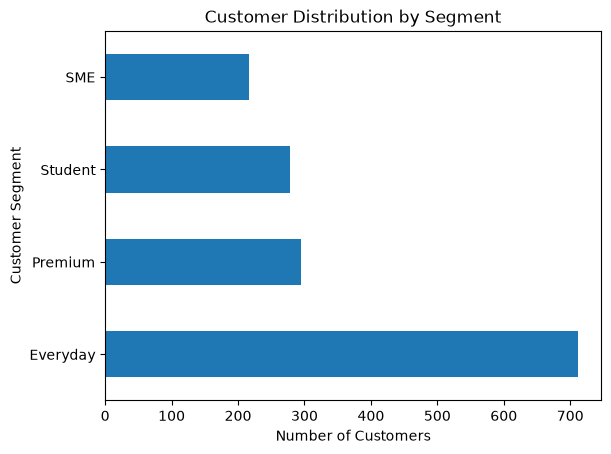

In [56]:
customers["Customer_Segment"].value_counts().plot(
    kind="barh",
    title="Customer Distribution by Segment",
    xlabel="Number of Customers",
    ylabel="Customer Segment"
)

In [57]:

  transactions = pd.read_csv("FinTrust_Transaction_Data.csv")

In [58]:
transactions.shape

(12000, 11)

In [59]:
transactions.head()

,Transaction_ID,Customer_ID,Transaction_DateTime,Transaction_Type,Amount_NGN,Channel,Device_Type,Location,International_Transaction,Transaction_Status,Risk_Review_Flag
0,FT-T000001,FT-C01135,1/1/2026 0:00,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes
1,FT-T000002,FT-C00428,1/1/2026 0:10,Cash Withdrawal,11681.12,ATM,Android,Kaduna,No,Successful,Yes
2,FT-T000003,FT-C00469,1/1/2026 0:21,Transfer,571.91,ATM,POS Terminal,Kano,No,Successful,No
3,FT-T000004,FT-C01015,1/1/2026 0:32,Deposit,105367.52,Mobile App,Web Browser,Abuja,No,Successful,No
4,FT-T000005,FT-C00870,1/1/2026 0:43,Cash Withdrawal,3049.06,Mobile App,POS Terminal,Abuja,No,Successful,No


In [60]:
transactions.columns

Index(['Transaction_ID', 'Customer_ID', 'Transaction_DateTime',
       'Transaction_Type', 'Amount_NGN', 'Channel', 'Device_Type', 'Location',
       'International_Transaction', 'Transaction_Status', 'Risk_Review_Flag'],
      dtype='str')

In [61]:
transactions.isnull().sum()

Transaction_ID                0
Customer_ID                   0
Transaction_DateTime          0
Transaction_Type              0
Amount_NGN                    0
Channel                       0
Device_Type                  96
Location                     96
International_Transaction     0
Transaction_Status            0
Risk_Review_Flag              0
dtype: int64

In [62]:
transactions["Transaction_Type"].value_counts()

Transaction_Type
Transfer           3549
Card Purchase      3033
Bill Payment       1475
Cash Withdrawal    1430
Deposit            1328
Airtime/Data       1185
Name: count, dtype: int64

In [63]:
transactions.groupby("Transaction_Type")["Amount_NGN"].sum().sort_values(ascending=False)

Transaction_Type
Transfer           2.379167e+08
Deposit            1.309851e+08
Card Purchase      8.586341e+07
Cash Withdrawal    6.777236e+07
Bill Payment       2.816365e+07
Airtime/Data       9.776171e+06
Name: Amount_NGN, dtype: float64

In [64]:
transactions.groupby("Transaction_Type")["Amount_NGN"].sum().sort_values(ascending=False).apply(lambda x: f"₦{x:,.2f}")

Transaction_Type
Transfer           ₦237,916,700.41
Deposit            ₦130,985,059.85
Card Purchase       ₦85,863,413.78
Cash Withdrawal     ₦67,772,362.11
Bill Payment        ₦28,163,647.51
Airtime/Data         ₦9,776,171.19
Name: Amount_NGN, dtype: str

In [65]:
transactions.groupby("Transaction_Type")["Amount_NGN"].mean().sort_values(ascending=False)

Transaction_Type
Deposit            98633.328200
Transfer           67037.672699
Cash Withdrawal    47393.260217
Card Purchase      28309.730887
Bill Payment       19093.998312
Airtime/Data        8249.933494
Name: Amount_NGN, dtype: float64

<Axes: xlabel='Transaction_Type'>

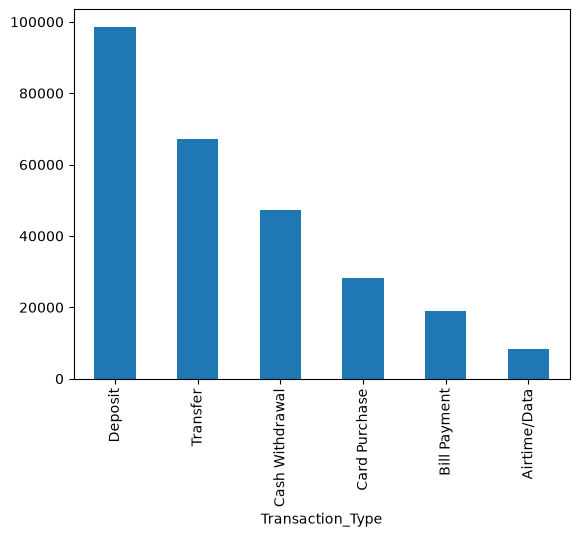

In [66]:
transactions.groupby("Transaction_Type")["Amount_NGN"].mean().sort_values(ascending=False).plot(kind="bar")

In [ ]:
transactions["Transaction_DateTime"] = pd.to_datetime(
    transactions["Transaction_DateTime"],
    format="%m/%d/%Y %H:%M",
    errors="raise"
)

transactions["Month"] = transactions["Transaction_DateTime"].dt.to_period("M")

In [ ]:
transactions["Transaction_DateTime"] = pd.to_datetime(
    transactions["Transaction_DateTime"],
    format="%m/%d/%Y %H:%M",
    errors="raise"
)

transactions["Month"] = transactions["Transaction_DateTime"].dt.to_period("M")

In [69]:
transactions.groupby("Month").size()

Month
2026-01    4133
2026-02    3734
2026-03    4133
Freq: M, dtype: int64

In [70]:
transactions.groupby("Month")["Amount_NGN"].sum()

Month
2026-01    1.884894e+08
2026-02    1.757869e+08
2026-03    1.962010e+08
Freq: M, Name: Amount_NGN, dtype: float64

In [71]:
transactions.groupby("Month")["Amount_NGN"].sum().apply(lambda x: f"₦{x:,.2f}")

Month
2026-01    ₦188,489,434.69
2026-02    ₦175,786,896.99
2026-03    ₦196,201,023.17
Freq: M, Name: Amount_NGN, dtype: str

<Axes: xlabel='Month'>

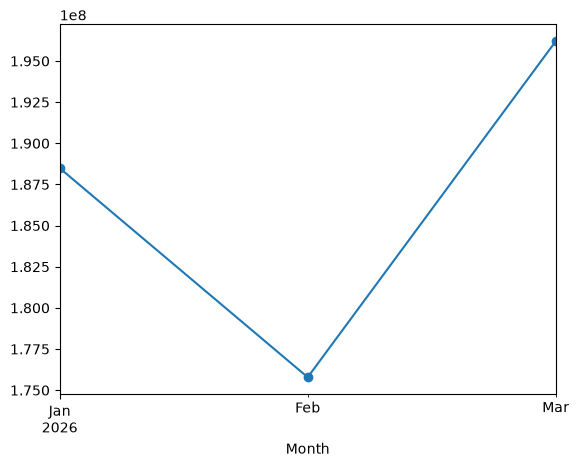

In [72]:
transactions.groupby("Month")["Amount_NGN"].sum().plot(kind="line", marker="o")

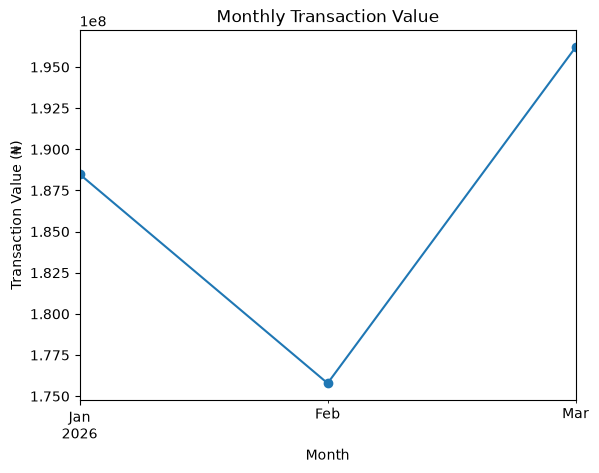

In [73]:
monthly_value = transactions.groupby("Month")["Amount_NGN"].sum()

monthly_value.plot(
    kind="line",
    marker="o",
    title="Monthly Transaction Value"
)

plt.xlabel("Month")
plt.ylabel("Transaction Value (₦)")
plt.xticks(rotation=0)
plt.show()

In [74]:
import matplotlib.pyplot as plt

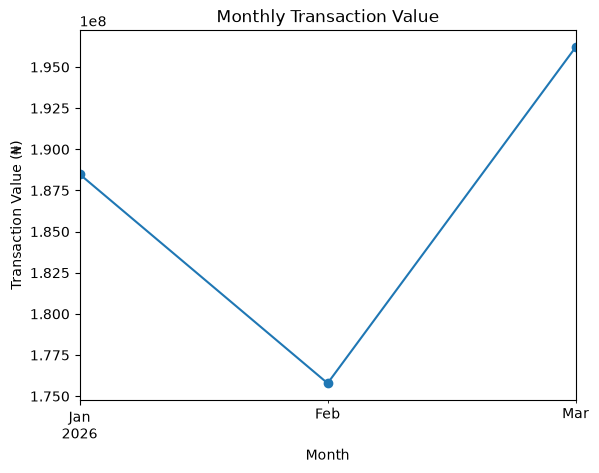

In [75]:
monthly_value = transactions.groupby("Month")["Amount_NGN"].sum()

monthly_value.plot(
    kind="line",
    marker="o",
    title="Monthly Transaction Value"
)

plt.xlabel("Month")
plt.ylabel("Transaction Value (₦)")
plt.xticks(rotation=0)
plt.show()

In [76]:
transactions["Transaction_Status"].value_counts()

Transaction_Status
Successful    10856
Failed          630
Reversed        326
Pending         188
Name: count, dtype: int64

In [77]:
transactions["Transaction_Status"].value_counts(normalize=True) * 100

Transaction_Status
Successful    90.466667
Failed         5.250000
Reversed       2.716667
Pending        1.566667
Name: proportion, dtype: float64

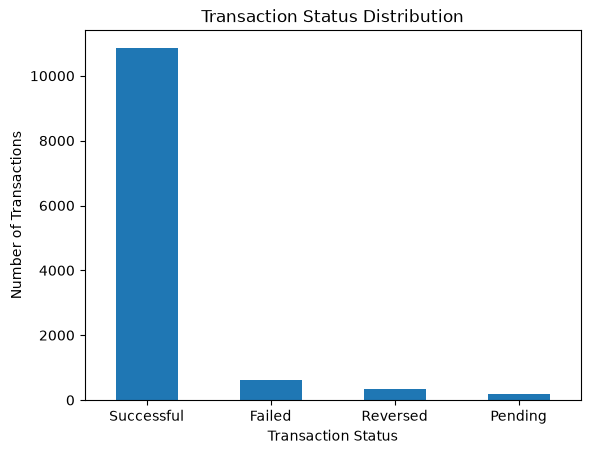

In [78]:
transactions["Transaction_Status"].value_counts().plot(
    kind="bar",
    title="Transaction Status Distribution"
)

plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

In [79]:
transactions["Channel"].value_counts()

Channel
Mobile App    5102
POS           2393
Web           1869
ATM           1747
USSD           889
Name: count, dtype: int64

In [80]:
transactions.groupby("Channel")["Amount_NGN"].sum().sort_values(ascending=False)

Channel
Mobile App    2.401044e+08
POS           1.043467e+08
Web           8.932500e+07
ATM           8.394235e+07
USSD          4.275895e+07
Name: Amount_NGN, dtype: float64

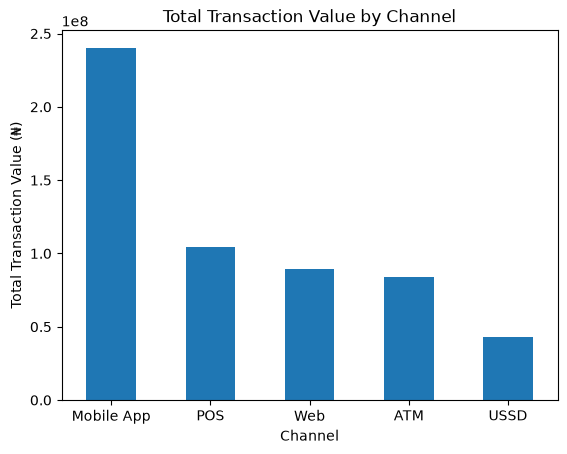

In [81]:
transactions.groupby("Channel")["Amount_NGN"].sum().sort_values(ascending=False).plot(
    kind="bar",
    title="Total Transaction Value by Channel"
)

plt.xlabel("Channel")
plt.ylabel("Total Transaction Value (₦)")
plt.xticks(rotation=0)
plt.show()

In [82]:
transactions.merge(
    customers[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="left"
)["Customer_Segment"].value_counts()

Customer_Segment
Everyday    5644
Premium     2361
Student     2289
SME         1706
Name: count, dtype: int64

In [83]:
id="8k2mqp"
segment_value = transactions.merge(
    customers[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="left"
).groupby("Customer_Segment")["Amount_NGN"].sum().sort_values(ascending=False)

segment_value

Customer_Segment
Everyday    2.614589e+08
Premium     1.077512e+08
Student     1.074759e+08
SME         8.379137e+07
Name: Amount_NGN, dtype: float64

In [84]:
transactions.merge(
    customers[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="left"
).groupby("Customer_Segment")["Amount_NGN"].mean().sort_values(ascending=False)

Customer_Segment
SME         49115.692679
Student     46953.196300
Everyday    46325.110027
Premium     45637.948251
Name: Amount_NGN, dtype: float64

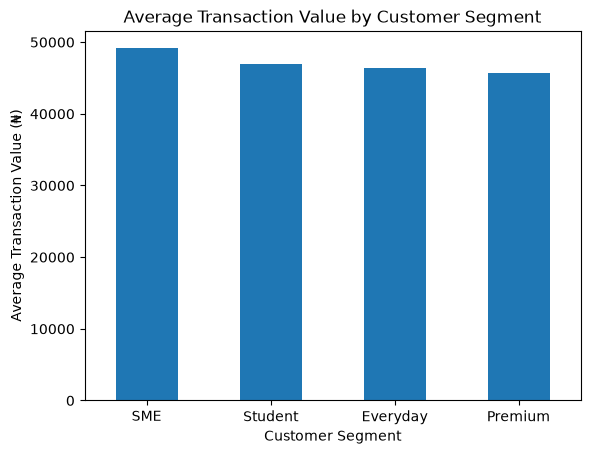

In [85]:
transactions.merge(
    customers[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="left"
).groupby("Customer_Segment")["Amount_NGN"].mean().sort_values(ascending=False).plot(
    kind="bar",
    title="Average Transaction Value by Customer Segment"
)

plt.xlabel("Customer Segment")
plt.ylabel("Average Transaction Value (₦)")
plt.xticks(rotation=0)
plt.show()

In [86]:
transactions.merge(
    customers[["Customer_ID", "Account_Type"]],
    on="Customer_ID",
    how="left"
)["Account_Type"].value_counts()

Account_Type
Savings    7149
Current    3023
Premium    1828
Name: count, dtype: int64

In [87]:
transactions.merge(
    customers[["Customer_ID", "Account_Type"]],
    on="Customer_ID",
    how="left"
)["Account_Type"].value_counts()

Account_Type
Savings    7149
Current    3023
Premium    1828
Name: count, dtype: int64

In [88]:
transactions.merge(
    customers[["Customer_ID", "Account_Type"]],
    on="Customer_ID",
    how="left"
).groupby("Account_Type")["Amount_NGN"].sum().sort_values(ascending=False)

Account_Type
Savings    3.355895e+08
Current    1.434389e+08
Premium    8.144892e+07
Name: Amount_NGN, dtype: float64

In [89]:
transactions.merge(
    customers[["Customer_ID", "Account_Type"]],
    on="Customer_ID",
    how="left"
).groupby("Account_Type")["Amount_NGN"].mean().sort_values(ascending=False)

Account_Type
Current    47449.203222
Savings    46942.158463
Premium    44556.303425
Name: Amount_NGN, dtype: float64

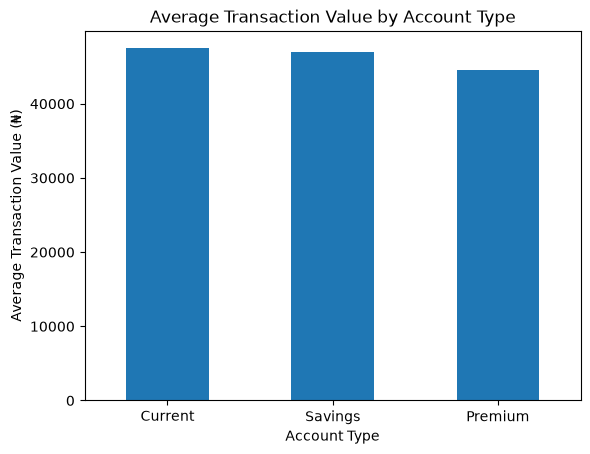

In [90]:
transactions.merge(
    customers[["Customer_ID", "Account_Type"]],
    on="Customer_ID",
    how="left"
).groupby("Account_Type")["Amount_NGN"].mean().sort_values(ascending=False).plot(
    kind="bar",
    title="Average Transaction Value by Account Type"
)

plt.xlabel("Account Type")
plt.ylabel("Average Transaction Value (₦)")
plt.xticks(rotation=0)
plt.show()

In [91]:
transactions["Location"].value_counts()

Location
Ibadan           1550
Kano             1526
Port Harcourt    1520
Enugu            1484
Kaduna           1481
Abuja            1461
Benin City       1451
Lagos            1431
Name: count, dtype: int64

In [92]:
location_volume = (
    transactions.groupby("Location")
    .size()
    .sort_values(ascending=False)
)

location_volume

Location
Ibadan           1550
Kano             1526
Port Harcourt    1520
Enugu            1484
Kaduna           1481
Abuja            1461
Benin City       1451
Lagos            1431
dtype: int64

In [93]:
location_value = (
    transactions.groupby("Location")["Amount_NGN"]
    .sum()
    .sort_values(ascending=False)
)

location_value

Location
Ibadan           81415629.64
Kano             74414462.27
Port Harcourt    71379838.80
Kaduna           70378742.65
Enugu            69101538.42
Lagos            63978344.62
Benin City       63387171.11
Abuja            62051569.38
Name: Amount_NGN, dtype: float64

In [94]:
location_average = (
    transactions.groupby("Location")["Amount_NGN"]
    .mean()
    .sort_values(ascending=False)
)

location_average

Location
Ibadan           52526.212671
Kano             48764.392051
Kaduna           47521.095645
Port Harcourt    46960.420263
Enugu            46564.378989
Lagos            44708.836212
Benin City       43685.162722
Abuja            42471.984517
Name: Amount_NGN, dtype: float64

In [95]:
location_summary = (
    transactions.groupby("Location")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Value_NGN=("Amount_NGN", "sum"),
        Average_Value_NGN=("Amount_NGN", "mean")
    )
    .sort_values("Total_Value_NGN", ascending=False)
)

location_summary

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
Location,,,
Ibadan,1550,81415629.64,52526.212671
Kano,1526,74414462.27,48764.392051
Port Harcourt,1520,71379838.80,46960.420263
Kaduna,1481,70378742.65,47521.095645
Enugu,1484,69101538.42,46564.378989
Lagos,1431,63978344.62,44708.836212
Benin City,1451,63387171.11,43685.162722
Abuja,1461,62051569.38,42471.984517


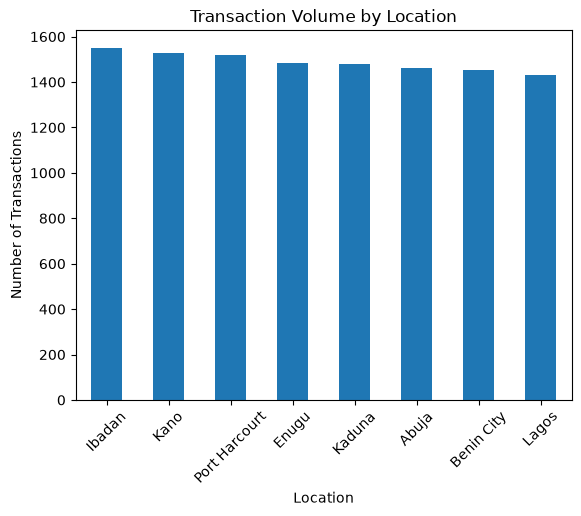

In [96]:
location_volume.plot(
    kind="bar",
    title="Transaction Volume by Location"
)

plt.xlabel("Location")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

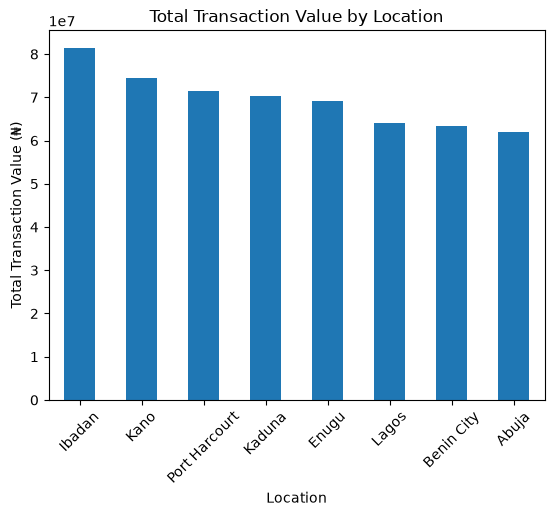

In [97]:
location_value.plot(
    kind="bar",
    title="Total Transaction Value by Location"
)

plt.xlabel("Location")
plt.ylabel("Total Transaction Value (₦)")
plt.xticks(rotation=45)
plt.show()

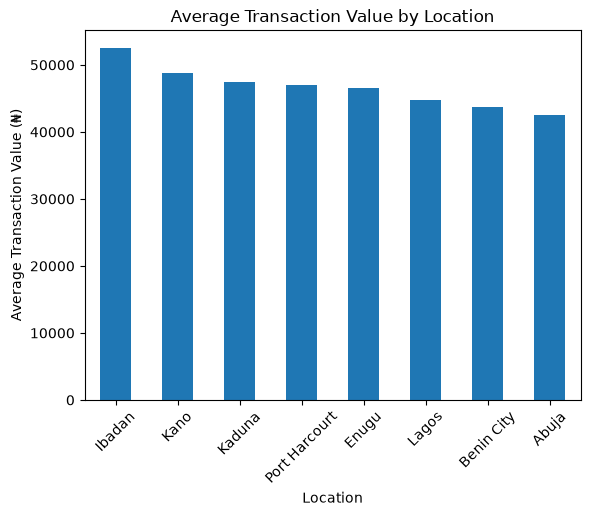

In [98]:
location_average.plot(
    kind="bar",
    title="Average Transaction Value by Location"
)

plt.xlabel("Location")
plt.ylabel("Average Transaction Value (₦)")
plt.xticks(rotation=45)
plt.show()

In [99]:
international_count = (
    transactions["International_Transaction"]
    .value_counts()
)

international_count

International_Transaction
No     11520
Yes      480
Name: count, dtype: int64

In [100]:
international_percentage = (
    transactions["International_Transaction"]
    .value_counts(normalize=True) * 100
)

international_percentage

International_Transaction
No     96.0
Yes     4.0
Name: proportion, dtype: float64

In [101]:
international_value = (
    transactions.groupby("International_Transaction")["Amount_NGN"]
    .sum()
    .sort_values(ascending=False)
)

international_value

International_Transaction
No     5.404816e+08
Yes    1.999578e+07
Name: Amount_NGN, dtype: float64

In [102]:
international_average = (
    transactions.groupby("International_Transaction")["Amount_NGN"]
    .mean()
    .sort_values(ascending=False)
)

international_average

International_Transaction
No     46916.803036
Yes    41657.883063
Name: Amount_NGN, dtype: float64

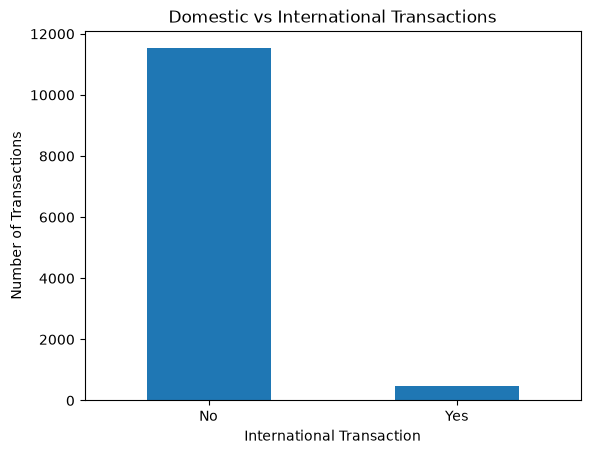

In [103]:
international_count.plot(
    kind="bar",
    title="Domestic vs International Transactions"
)

plt.xlabel("International Transaction")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

In [104]:
risk_count = (
    transactions["Risk_Review_Flag"]
    .value_counts()
)

risk_count

Risk_Review_Flag
No     9648
Yes    2352
Name: count, dtype: int64

In [105]:
risk_percentage = (
    transactions["Risk_Review_Flag"]
    .value_counts(normalize=True) * 100
)

risk_percentage

Risk_Review_Flag
No     80.4
Yes    19.6
Name: proportion, dtype: float64

In [106]:
risk_average = (
    transactions.groupby("Risk_Review_Flag")["Amount_NGN"]
    .mean()
    .sort_values(ascending=False)
)

risk_average

Risk_Review_Flag
Yes    68785.557572
No     41323.976310
Name: Amount_NGN, dtype: float64

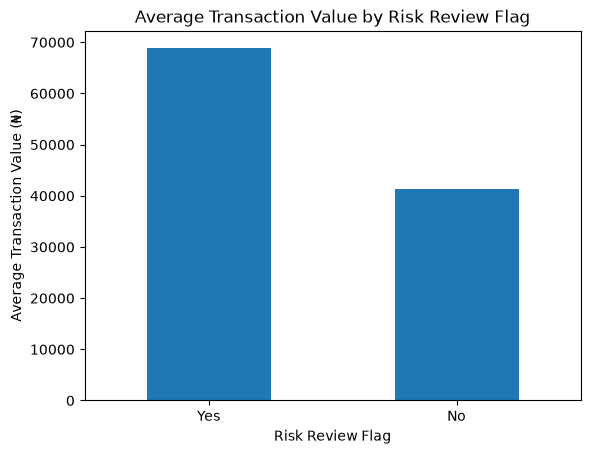

In [107]:
risk_average.plot(
    kind="bar",
    title="Average Transaction Value by Risk Review Flag"
)

plt.xlabel("Risk Review Flag")
plt.ylabel("Average Transaction Value (₦)")
plt.xticks(rotation=0)
plt.show()

In [108]:
risk_by_type = (
    transactions.groupby("Transaction_Type")["Risk_Review_Flag"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

risk_by_type

Transaction_Type
Transfer           28.486898
Cash Withdrawal    25.314685
Deposit            16.189759
Airtime/Data       15.189873
Card Purchase      13.023409
Bill Payment       12.813559
Name: Risk_Review_Flag, dtype: float64

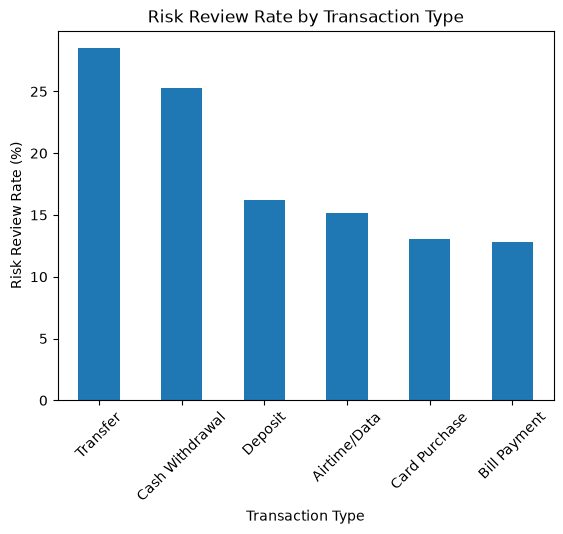

In [109]:
risk_by_type.plot(
    kind="bar",
    title="Risk Review Rate by Transaction Type"
)

plt.xlabel("Transaction Type")
plt.ylabel("Risk Review Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [110]:
transactions.isnull().sum()

Transaction_ID                0
Customer_ID                   0
Transaction_DateTime          0
Transaction_Type              0
Amount_NGN                    0
Channel                       0
Device_Type                  96
Location                     96
International_Transaction     0
Transaction_Status            0
Risk_Review_Flag              0
Month                         0
dtype: int64

In [111]:
missing_device = transactions[transactions["Device_Type"].isnull()]

missing_device[["Transaction_ID", "Device_Type", "Location"]].head(10)

,Transaction_ID,Device_Type,Location
56,FT-T000057,NaN,Ibadan
350,FT-T000351,NaN,Port Harcourt
452,FT-T000453,NaN,Enugu
481,FT-T000482,NaN,Abuja
650,FT-T000651,NaN,Port Harcourt
690,FT-T000691,NaN,Abuja
742,FT-T000743,NaN,Benin City
853,FT-T000854,NaN,Enugu
895,FT-T000896,NaN,Port Harcourt
1069,FT-T001070,NaN,Lagos


In [112]:
missing_location = transactions[transactions["Location"].isnull()]

missing_location[["Transaction_ID", "Device_Type", "Location"]].head(10)

,Transaction_ID,Device_Type,Location
35,FT-T000036,Android,NaN
88,FT-T000089,Web Browser,NaN
124,FT-T000125,ATM Terminal,NaN
269,FT-T000270,iOS,NaN
287,FT-T000288,Android,NaN
363,FT-T000364,iOS,NaN
397,FT-T000398,iOS,NaN
428,FT-T000429,Web Browser,NaN
652,FT-T000653,Android,NaN
665,FT-T000666,Android,NaN


In [113]:
pd.crosstab(
    transactions["Device_Type"].isnull(),
    transactions["Location"].isnull()
)

Location,False,True
Device_Type,,
False,11812,92
True,92,4


In [114]:
Q1 = transactions["Amount_NGN"].quantile(0.25)
Q3 = transactions["Amount_NGN"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2192.22
Q3: 48484.475
IQR: 46292.255
Lower Bound: -67246.16249999999
Upper Bound: 117922.85749999998


In [115]:
outliers = transactions[
    (transactions["Amount_NGN"] < lower_bound) |
    (transactions["Amount_NGN"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Number of potential outliers: 1474


# FINTRUST DIGITAL BANK
## Week 2 Data Analytics — Python EDA

In [116]:
import pandas as pd

In [117]:
customer_df = pd.read_csv("FinTrust_Customer_Data.csv")

In [118]:
transaction_df = pd.read_csv("FinTrust_Transaction_Data.csv")

In [119]:
print("Customer dataset shape:", customer_df.shape)
print("Transaction dataset shape:", transaction_df.shape)

Customer dataset shape: (1500, 12)
Transaction dataset shape: (12000, 11)


In [120]:
customer_df.head()

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Segment,Account_Type,Tenure_Months,Digital_Engagement_Score,Monthly_Income_Band,Preferred_Channel,Account_Status
0,FT-C00001,Ibrahim Adeyemi,56,Male,Lagos,Premium,Savings,55,84.9,500k-999k,Mobile App,Active
1,FT-C00002,Yusuf Mohammed,46,Male,Kano,Everyday,Current,79,50.7,500k-999k,Mobile App,Active
2,FT-C00003,Emeka Adeyemi,32,Female,Port Harcourt,Everyday,Savings,43,56.1,1m+,Mobile App,Active
3,FT-C00004,David Williams,60,Female,Benin City,Premium,Premium,44,54.0,500k-999k,Mobile App,Dormant
4,FT-C00005,Blessing Adeyemi,25,Male,Kaduna,Premium,Savings,68,85.1,500k-999k,Mobile App,Active


In [121]:
transaction_df.head()

,Transaction_ID,Customer_ID,Transaction_DateTime,Transaction_Type,Amount_NGN,Channel,Device_Type,Location,International_Transaction,Transaction_Status,Risk_Review_Flag
0,FT-T000001,FT-C01135,1/1/2026 0:00,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes
1,FT-T000002,FT-C00428,1/1/2026 0:10,Cash Withdrawal,11681.12,ATM,Android,Kaduna,No,Successful,Yes
2,FT-T000003,FT-C00469,1/1/2026 0:21,Transfer,571.91,ATM,POS Terminal,Kano,No,Successful,No
3,FT-T000004,FT-C01015,1/1/2026 0:32,Deposit,105367.52,Mobile App,Web Browser,Abuja,No,Successful,No
4,FT-T000005,FT-C00870,1/1/2026 0:43,Cash Withdrawal,3049.06,Mobile App,POS Terminal,Abuja,No,Successful,No


In [122]:
print("CUSTOMER DATA TYPES")
print(customer_df.dtypes)

print("\nTRANSACTION DATA TYPES")
print(transaction_df.dtypes)

CUSTOMER DATA TYPES
Customer_ID                     str
Customer_Name                   str
Age                           int64
Gender                          str
City                            str
Customer_Segment                str
Account_Type                    str
Tenure_Months                 int64
Digital_Engagement_Score    float64
Monthly_Income_Band             str
Preferred_Channel               str
Account_Status                  str
dtype: object

TRANSACTION DATA TYPES
Transaction_ID                   str
Customer_ID                      str
Transaction_DateTime             str
Transaction_Type                 str
Amount_NGN                   float64
Channel                          str
Device_Type                      str
Location                         str
International_Transaction        str
Transaction_Status               str
Risk_Review_Flag                 str
dtype: object


In [123]:
print("CUSTOMER MISSING VALUES")
print(customer_df.isnull().sum())

print("\nTRANSACTION MISSING VALUES")
print(transaction_df.isnull().sum())

CUSTOMER MISSING VALUES
Customer_ID                 0
Customer_Name               0
Age                         0
Gender                      0
City                        0
Customer_Segment            0
Account_Type                0
Tenure_Months               0
Digital_Engagement_Score    0
Monthly_Income_Band         0
Preferred_Channel           0
Account_Status              0
dtype: int64

TRANSACTION MISSING VALUES
Transaction_ID                0
Customer_ID                   0
Transaction_DateTime          0
Transaction_Type              0
Amount_NGN                    0
Channel                       0
Device_Type                  96
Location                     96
International_Transaction     0
Transaction_Status            0
Risk_Review_Flag              0
dtype: int64


In [124]:
print("Duplicate customer records:", customer_df.duplicated().sum())
print("Duplicate transaction records:", transaction_df.duplicated().sum())

print("Duplicate Customer_IDs:", customer_df["Customer_ID"].duplicated().sum())
print("Duplicate Transaction_IDs:", transaction_df["Transaction_ID"].duplicated().sum())

Duplicate customer records: 0
Duplicate transaction records: 0
Duplicate Customer_IDs: 0
Duplicate Transaction_IDs: 0


In [125]:
customer_df[["Age", "Tenure_Months", "Digital_Engagement_Score"]].describe()

,Age,Tenure_Months,Digital_Engagement_Score
count,1500.000000,1500.000000,1500.000000
mean,41.587333,49.858667,67.954000
std,13.733127,27.910990,17.555376
min,18.000000,1.000000,16.700000
25%,29.750000,26.000000,56.100000
50%,42.000000,51.000000,68.000000
75%,53.000000,74.000000,80.925000
max,65.000000,96.000000,100.000000


In [126]:
customer_df["Customer_Segment"].value_counts()

Customer_Segment
Everyday    711
Premium     295
Student     278
SME         216
Name: count, dtype: int64

In [127]:
customer_df["Preferred_Channel"].value_counts()

Preferred_Channel
Mobile App    924
Web           357
USSD          219
Name: count, dtype: int64

In [128]:
customer_df["Account_Status"].value_counts()

Account_Status
Active        1367
Dormant        107
Restricted      26
Name: count, dtype: int64

In [129]:
transaction_df["Amount_NGN"].describe().round(2)

count     12000.00
mean      46706.45
std       86028.72
min         100.17
25%        2192.22
50%       10305.94
75%       48484.48
max      693454.45
Name: Amount_NGN, dtype: float64

In [130]:
transaction_df["Transaction_Type"].value_counts()

Transaction_Type
Transfer           3549
Card Purchase      3033
Bill Payment       1475
Cash Withdrawal    1430
Deposit            1328
Airtime/Data       1185
Name: count, dtype: int64

In [131]:
transaction_df["Channel"].value_counts()

Channel
Mobile App    5102
POS           2393
Web           1869
ATM           1747
USSD           889
Name: count, dtype: int64

In [132]:
transaction_df["Transaction_Status"].value_counts()

Transaction_Status
Successful    10856
Failed          630
Reversed        326
Pending         188
Name: count, dtype: int64

In [133]:
transaction_df["Risk_Review_Flag"].value_counts()

Risk_Review_Flag
No     9648
Yes    2352
Name: count, dtype: int64

In [ ]:
transaction_df["Transaction_DateTime"] = pd.to_datetime(
    transaction_df["Transaction_DateTime"],
    format="%m/%d/%Y %H:%M",
    errors="raise"
)
transaction_df["Month"] = transaction_df["Transaction_DateTime"].dt.to_period("M")

In [135]:
monthly_summary = transaction_df.groupby("Month").agg(
    Transaction_Count=("Transaction_ID", "count"),
    Total_Value_NGN=("Amount_NGN", "sum"),
    Average_Value_NGN=("Amount_NGN", "mean")
)

monthly_summary.style.format({
    "Total_Value_NGN": "{:,.2f}",
    "Average_Value_NGN": "{:,.2f}"
})

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
Month,,,
2026-01,4133,"188,489,434.69","45,605.96"
2026-02,3734,"175,786,896.99","47,077.37"
2026-03,4133,"196,201,023.17","47,471.82"


In [136]:
transaction_type_summary = transaction_df.groupby("Transaction_Type").agg(
    Transaction_Count=("Transaction_ID", "count"),
    Total_Value_NGN=("Amount_NGN", "sum"),
    Average_Value_NGN=("Amount_NGN", "mean")
).sort_values("Total_Value_NGN", ascending=False)

transaction_type_summary.style.format({
    "Total_Value_NGN": "{:,.2f}",
    "Average_Value_NGN": "{:,.2f}"
})

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
Transaction_Type,,,
Transfer,3549,"237,916,700.41","67,037.67"
Deposit,1328,"130,985,059.85","98,633.33"
Card Purchase,3033,"85,863,413.78","28,309.73"
Cash Withdrawal,1430,"67,772,362.11","47,393.26"
Bill Payment,1475,"28,163,647.51","19,094.00"
Airtime/Data,1185,"9,776,171.19","8,249.93"


In [137]:
channel_summary = transaction_df.groupby("Channel").agg(
    Transaction_Count=("Transaction_ID", "count"),
    Total_Value_NGN=("Amount_NGN", "sum"),
    Average_Value_NGN=("Amount_NGN", "mean")
).sort_values("Total_Value_NGN", ascending=False)

channel_summary.style.format({
    "Total_Value_NGN": "{:,.2f}",
    "Average_Value_NGN": "{:,.2f}"
})

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
Channel,,,
Mobile App,5102,"240,104,365.19","47,060.83"
POS,2393,"104,346,681.23","43,604.96"
Web,1869,"89,324,999.94","47,792.94"
ATM,1747,"83,942,354.23","48,049.43"
USSD,889,"42,758,954.26","48,097.81"


In [138]:
risk_summary = transaction_df.groupby("Risk_Review_Flag").agg(
    Transaction_Count=("Transaction_ID", "count"),
    Total_Value_NGN=("Amount_NGN", "sum"),
    Average_Value_NGN=("Amount_NGN", "mean")
)

risk_summary.style.format({
    "Total_Value_NGN": "{:,.2f}",
    "Average_Value_NGN": "{:,.2f}"
})

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
Risk_Review_Flag,,,
No,9648,"398,693,723.44","41,323.98"
Yes,2352,"161,783,631.41","68,785.56"


In [139]:
merged_df = transaction_df.merge(
    customer_df,
    on="Customer_ID",
    how="left"
)

print("Merged dataset shape:", merged_df.shape)

Merged dataset shape: (12000, 23)


In [140]:
print("Unmatched customer records:",
      merged_df["Customer_Name"].isnull().sum())

Unmatched customer records: 0


In [141]:
segment_summary = merged_df.groupby("Customer_Segment").agg(
    Transaction_Count=("Transaction_ID", "count"),
    Total_Value_NGN=("Amount_NGN", "sum"),
    Average_Value_NGN=("Amount_NGN", "mean")
).sort_values("Total_Value_NGN", ascending=False)

segment_summary.style.format({
    "Total_Value_NGN": "{:,.2f}",
    "Average_Value_NGN": "{:,.2f}"
})

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
Customer_Segment,,,
Everyday,5644,"261,458,920.99","46,325.11"
Premium,2361,"107,751,195.82","45,637.95"
Student,2289,"107,475,866.33","46,953.20"
SME,1706,"83,791,371.71","49,115.69"


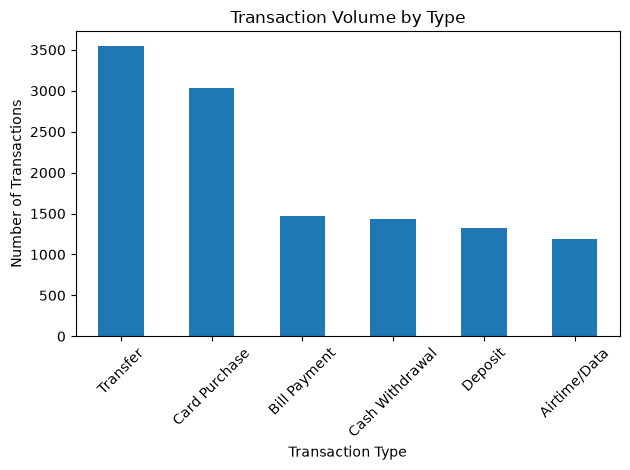

In [142]:
import matplotlib.pyplot as plt
transaction_type_counts = transaction_df["Transaction_Type"].value_counts()

transaction_type_counts.plot(kind="bar")

plt.title("Transaction Volume by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

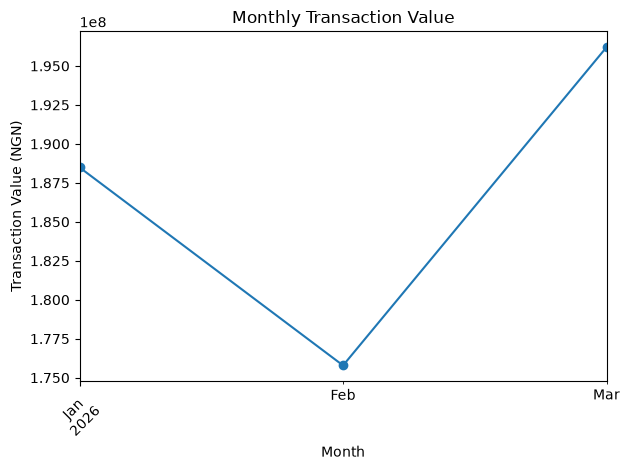

In [143]:
monthly_summary["Total_Value_NGN"].plot(kind="line", marker="o")

plt.title("Monthly Transaction Value")
plt.xlabel("Month")
plt.ylabel("Transaction Value (NGN)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

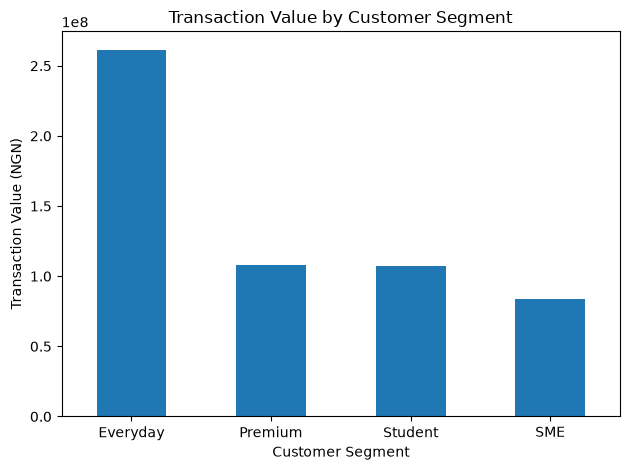

In [144]:
segment_summary["Total_Value_NGN"].plot(kind="bar")

plt.title("Transaction Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Transaction Value (NGN)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

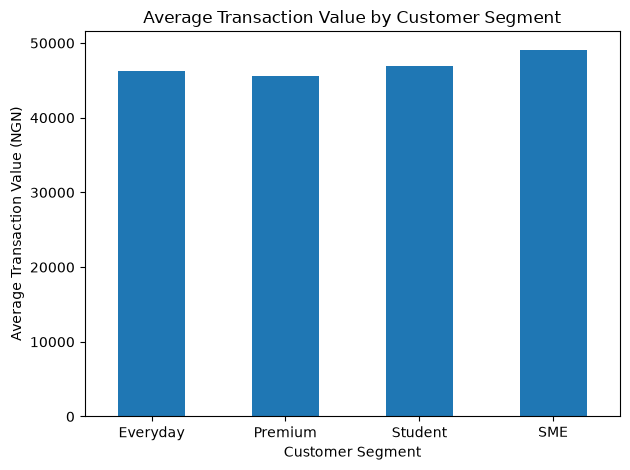

In [145]:
segment_summary["Average_Value_NGN"].plot(kind="bar")

plt.title("Average Transaction Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Transaction Value (NGN)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Key Python EDA Findings

1. FinTrust contains 1,500 customer records and 12,000 transaction records.

2. The transaction dataset contains 96 missing Device_Type values and 96 missing Location values.

3. Mobile App is the dominant transaction channel, with 5,102 transactions and approximately ₦240.1 million in transaction value.

4. Transfer is the largest transaction type by both transaction volume and total transaction value.

5. Everyday customers generate the highest transaction volume and total transaction value.

6. SME customers have the highest average transaction value at approximately ₦49,116.

7. March recorded the highest monthly transaction value at approximately ₦196.2 million.

8. Transactions labelled Risk_Review_Flag = Yes represent 19.6% of transactions and have a higher average transaction value than transactions labelled No.

9. The transaction data covers January 1 to March 31, 2026.

10. Risk_Review_Flag is a synthetic educational label and should not be interpreted as a real fraud determination.

In [146]:
customer_df["City"].value_counts()

City
Lagos            488
Abuja            223
Port Harcourt    172
Kano             159
Ibadan           148
Enugu            108
Kaduna           103
Benin City        99
Name: count, dtype: int64

In [147]:
pd.crosstab(
    customer_df["Customer_Segment"],
    customer_df["Preferred_Channel"]
)

Preferred_Channel,Mobile App,USSD,Web
Customer_Segment,,,
Everyday,440,113,158
Premium,181,38,76
SME,140,32,44
Student,163,36,79


In [148]:
customer_df.groupby("Customer_Segment")["Digital_Engagement_Score"].mean().round(2)

Customer_Segment
Everyday    68.37
Premium     66.71
SME         68.34
Student     67.91
Name: Digital_Engagement_Score, dtype: float64

In [149]:
channel_status = pd.crosstab(
    transaction_df["Channel"],
    transaction_df["Transaction_Status"],
    normalize="index"
) * 100

channel_status.round(2)

Transaction_Status,Failed,Pending,Reversed,Successful
Channel,,,,
ATM,4.18,1.43,2.69,91.70
Mobile App,5.80,1.61,2.84,89.75
POS,5.22,1.42,2.51,90.85
USSD,5.40,1.01,3.26,90.33
Web,4.71,2.03,2.41,90.85


In [150]:
risk_by_type = pd.crosstab(
    transaction_df["Transaction_Type"],
    transaction_df["Risk_Review_Flag"],
    normalize="index"
) * 100

risk_by_type.round(2)

Risk_Review_Flag,No,Yes
Transaction_Type,,
Airtime/Data,84.81,15.19
Bill Payment,87.19,12.81
Card Purchase,86.98,13.02
Cash Withdrawal,74.69,25.31
Deposit,83.81,16.19
Transfer,71.51,28.49


In [151]:
missing_pattern = transaction_df[
    transaction_df["Device_Type"].isnull() |
    transaction_df["Location"].isnull()
][["Transaction_ID", "Device_Type", "Location"]]

missing_pattern.head(20)

,Transaction_ID,Device_Type,Location
35,FT-T000036,Android,NaN
56,FT-T000057,NaN,Ibadan
88,FT-T000089,Web Browser,NaN
124,FT-T000125,ATM Terminal,NaN
269,FT-T000270,iOS,NaN
287,FT-T000288,Android,NaN
350,FT-T000351,NaN,Port Harcourt
363,FT-T000364,iOS,NaN
397,FT-T000398,iOS,NaN
428,FT-T000429,Web Browser,NaN


In [152]:
international_summary = transaction_df.groupby(
    "International_Transaction"
).agg(
    Transaction_Count=("Transaction_ID", "count"),
    Total_Value_NGN=("Amount_NGN", "sum"),
    Average_Value_NGN=("Amount_NGN", "mean")
)

international_summary.round(2)

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
International_Transaction,,,
No,11520,5.404816e+08,46916.80
Yes,480,1.999578e+07,41657.88


In [153]:
location_summary = transaction_df.groupby("Location").agg(
    Transaction_Count=("Transaction_ID", "count"),
    Total_Value_NGN=("Amount_NGN", "sum"),
    Average_Value_NGN=("Amount_NGN", "mean")
).sort_values("Total_Value_NGN", ascending=False)

location_summary.round(2)

,Transaction_Count,Total_Value_NGN,Average_Value_NGN
Location,,,
Ibadan,1550,81415629.64,52526.21
Kano,1526,74414462.27,48764.39
Port Harcourt,1520,71379838.80,46960.42
Kaduna,1481,70378742.65,47521.10
Enugu,1484,69101538.42,46564.38
Lagos,1431,63978344.62,44708.84
Benin City,1451,63387171.11,43685.16
Abuja,1461,62051569.38,42471.98


In [154]:
transaction_type_avg = transaction_df.groupby(
    "Transaction_Type"
)["Amount_NGN"].mean().sort_values(ascending=False)

transaction_type_avg.round(2)

Transaction_Type
Deposit            98633.33
Transfer           67037.67
Cash Withdrawal    47393.26
Card Purchase      28309.73
Bill Payment       19094.00
Airtime/Data        8249.93
Name: Amount_NGN, dtype: float64

In [155]:
channel_status_counts = pd.crosstab(
    transaction_df["Channel"],
    transaction_df["Transaction_Status"]
)

channel_status_counts

Transaction_Status,Failed,Pending,Reversed,Successful
Channel,,,,
ATM,73,25,47,1602
Mobile App,296,82,145,4579
POS,125,34,60,2174
USSD,48,9,29,803
Web,88,38,45,1698


In [156]:
risk_by_channel = pd.crosstab(
    transaction_df["Channel"],
    transaction_df["Risk_Review_Flag"],
    normalize="index"
) * 100

risk_by_channel.round(2)

Risk_Review_Flag,No,Yes
Channel,,
ATM,78.82,21.18
Mobile App,80.60,19.40
POS,81.65,18.35
USSD,82.68,17.32
Web,78.65,21.35


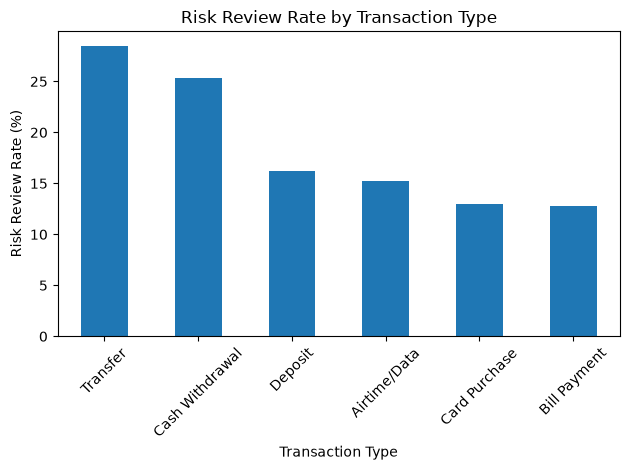

In [157]:
risk_by_type["Yes"].sort_values(ascending=False).plot(kind="bar")

plt.title("Risk Review Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Risk Review Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [158]:
print("Total transactions:", len(transaction_df))
print("Total transaction value:", round(transaction_df["Amount_NGN"].sum(), 2))
print("Average transaction value:", round(transaction_df["Amount_NGN"].mean(), 2))

Total transactions: 12000
Total transaction value: 560477354.85
Average transaction value: 46706.45


In [159]:
print("Earliest transaction:", transaction_df["Transaction_DateTime"].min())
print("Latest transaction:", transaction_df["Transaction_DateTime"].max())

Earliest transaction: 2026-01-01 00:00:00
Latest transaction: 2026-03-31 23:59:00


In [160]:
print("Customer records:", len(customer_df))
print("Transaction records:", len(transaction_df))
print("Duplicate Customer IDs:", customer_df["Customer_ID"].duplicated().sum())
print("Duplicate Transaction IDs:", transaction_df["Transaction_ID"].duplicated().sum())
print("Missing Device Type:", transaction_df["Device_Type"].isnull().sum())
print("Missing Location:", transaction_df["Location"].isnull().sum())
print("Unmatched customers after merge:", merged_df["Customer_Name"].isnull().sum())

Customer records: 1500
Transaction records: 12000
Duplicate Customer IDs: 0
Duplicate Transaction IDs: 0
Missing Device Type: 96
Missing Location: 96
Unmatched customers after merge: 0


## Python EDA Conclusion

The Python exploratory data analysis provided an overview of FinTrust's customer and transaction data for the period January to March 2026.

The analysis confirmed 1,500 customer records and 12,000 transaction records. The datasets contained no duplicate Customer_ID or Transaction_ID values, and all transaction records successfully matched a customer record after merging.

The main data-quality issues identified were 96 missing Device_Type values and 96 missing Location values in the transaction dataset. These values were retained for analysis because the missingness is part of the provided synthetic dataset.

The analysis showed that Mobile App transactions contributed the highest transaction volume and total transaction value. Everyday customers generated the highest transaction volume and total value, while SME customers recorded the highest average transaction value. March recorded the highest monthly transaction value during the analysis period.

The Risk_Review_Flag analysis identified differences in transaction values and review rates across transaction types and channels. However, this field is a synthetic educational label and should not be interpreted as a real fraud determination or banking risk decision.

Overall, the Python EDA confirms that the dataset is suitable for exploratory and business analysis, subject to the documented data-quality limitations.

# WEEK 3 — ADVANCED PYTHON ANALYSIS

## Deeper Exploratory Analysis and Validation

This section extends the Week 2 exploratory analysis by examining
transaction performance, customer behaviour, risk-review patterns,
channel performance, and monthly trends.

The analyses are used to validate and deepen the Week 2 business findings.

In [163]:
df = transaction_df

In [164]:
df.shape

(12000, 12)

In [165]:
channel_analysis = (
    df
    .groupby("Channel")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum"),
        Average_Transaction_Value=("Amount_NGN", "mean"),
        Successful_Transactions=("Transaction_Status", lambda x: (x == "Successful").sum())
    )
    .reset_index()
)

channel_analysis["Success_Rate"] = (
    channel_analysis["Successful_Transactions"]
    / channel_analysis["Transaction_Count"]
    * 100
)

channel_analysis = channel_analysis.sort_values(
    "Total_Transaction_Value",
    ascending=False
)

channel_analysis

,Channel,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value,Successful_Transactions,Success_Rate
1,Mobile App,5102,2.401044e+08,47060.832064,4579,89.749118
2,POS,2393,1.043467e+08,43604.964994,2174,90.848308
4,Web,1869,8.932500e+07,47792.937368,1698,90.850722
0,ATM,1747,8.394235e+07,48049.430011,1602,91.700057
3,USSD,889,4.275895e+07,48097.811316,803,90.326209


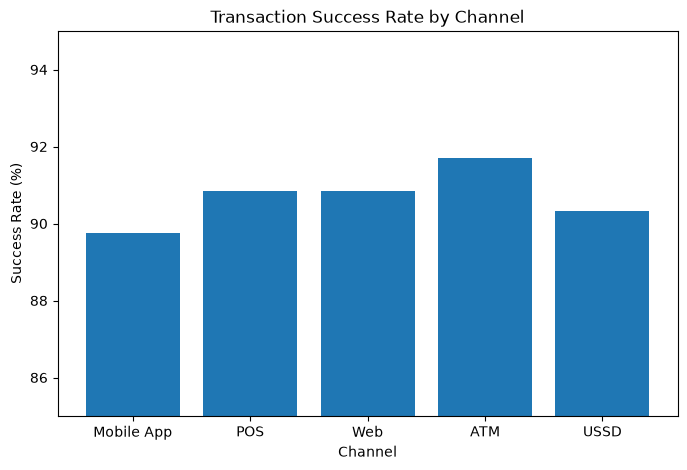

In [166]:
plt.figure(figsize=(8, 5))

plt.bar(
    channel_analysis["Channel"],
    channel_analysis["Success_Rate"]
)

plt.title("Transaction Success Rate by Channel")
plt.xlabel("Channel")
plt.ylabel("Success Rate (%)")
plt.ylim(85, 95)
plt.xticks(rotation=0)
plt.show()

## Finding — Transaction Success Rate by Channel

The analysis shows that ATM had the highest transaction success rate at approximately 91.70%, while Mobile App recorded the lowest at approximately 89.75%.

Although the difference between the channels is relatively small (about 1.95 percentage points), the Mobile App result is notable because it also has the highest transaction volume. This suggests that channel performance should be monitored alongside transaction volume rather than evaluated using transaction count alone.

This finding validates the Week 2 observation that the Mobile App is the dominant transaction channel while providing additional insight into its transaction success performance.

In [167]:
segment_analysis = (
    df
    .merge(
        customer_df[["Customer_ID", "Customer_Segment"]],
        on="Customer_ID",
        how="left"
    )
    .groupby("Customer_Segment")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum"),
        Average_Transaction_Value=("Amount_NGN", "mean")
    )
    .reset_index()
)

segment_analysis = segment_analysis.sort_values(
    "Total_Transaction_Value",
    ascending=False
)

segment_analysis

,Customer_Segment,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value
0,Everyday,5644,2.614589e+08,46325.110027
1,Premium,2361,1.077512e+08,45637.948251
3,Student,2289,1.074759e+08,46953.196300
2,SME,1706,8.379137e+07,49115.692679


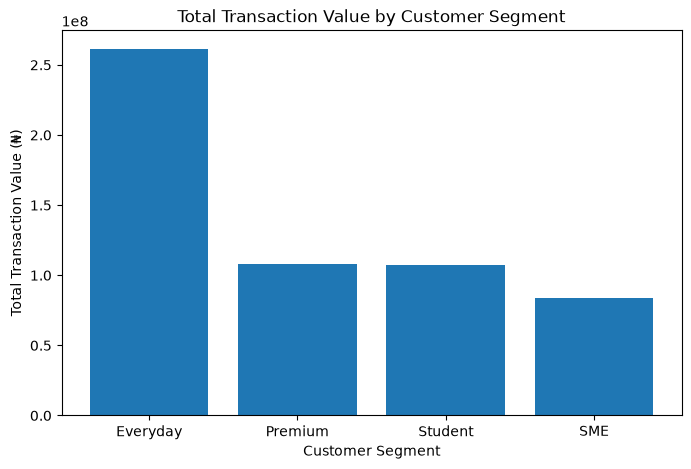

In [168]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_analysis["Customer_Segment"],
    segment_analysis["Total_Transaction_Value"]
)

plt.title("Total Transaction Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Transaction Value (₦)")
plt.xticks(rotation=0)
plt.show()

## Finding — Customer Segment Behaviour

The analysis shows that Everyday customers generated the highest transaction volume, with 5,644 transactions, and the highest total transaction value of approximately ₦261.46 million.

SME customers recorded the highest average transaction value at approximately ₦49,115.69, despite having the lowest transaction volume among the four customer segments.

This validates the Week 2 findings and provides a clearer view of how transaction volume and transaction value differ across customer segments. The results suggest that customer segments should be assessed using multiple measures rather than transaction volume alone.

In [169]:
risk_type_analysis = (
    df
    .groupby("Transaction_Type")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Risk_Review_Transactions=(
            "Risk_Review_Flag",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

risk_type_analysis["Risk_Review_Rate"] = (
    risk_type_analysis["Risk_Review_Transactions"]
    / risk_type_analysis["Transaction_Count"]
    * 100
)

risk_type_analysis = risk_type_analysis.sort_values(
    "Risk_Review_Rate",
    ascending=False
)

risk_type_analysis

,Transaction_Type,Transaction_Count,Risk_Review_Transactions,Risk_Review_Rate
5,Transfer,3549,1011,28.486898
3,Cash Withdrawal,1430,362,25.314685
4,Deposit,1328,215,16.189759
0,Airtime/Data,1185,180,15.189873
2,Card Purchase,3033,395,13.023409
1,Bill Payment,1475,189,12.813559


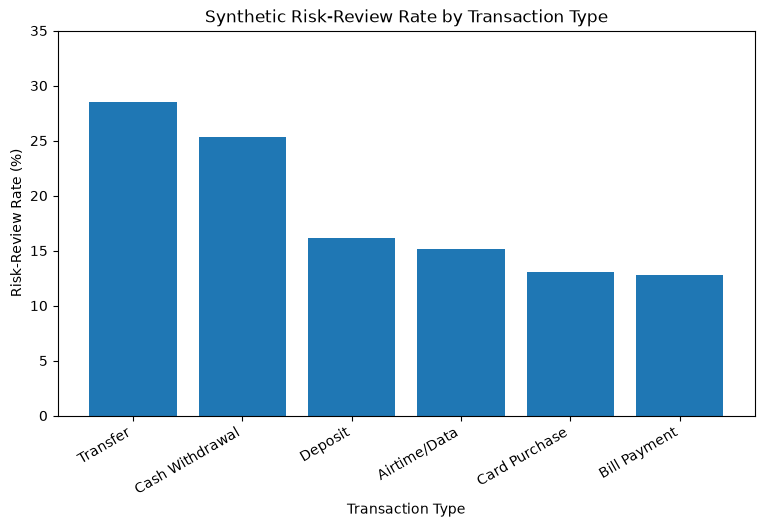

In [170]:
plt.figure(figsize=(9, 5))

plt.bar(
    risk_type_analysis["Transaction_Type"],
    risk_type_analysis["Risk_Review_Rate"]
)

plt.title("Synthetic Risk-Review Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Risk-Review Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 35)
plt.show()

### Finding — Synthetic Risk-Review Patterns by Transaction Type

The analysis shows that Transfer transactions had the highest synthetic risk-review rate at approximately 28.49%, followed by Cash Withdrawal at 25.31%. Bill Payment had the lowest rate at approximately 12.81%.

This provides a deeper breakdown of the overall risk-review pattern identified in Week 2 and shows that the synthetic review label varies considerably across transaction types.

Because the Risk_Review_Flag is a synthetic educational variable, these results should not be interpreted as evidence of actual fraud, suspicious activity, or banking risk. They are used only to demonstrate analytical review patterns within the training dataset.

In [ ]:
# Parse the stored timestamps explicitly as month/day/year.
# Direct SQLite retesting confirmed this format for all 12,000 records.
df["Transaction_DateTime_Parsed"] = pd.to_datetime(
    df["Transaction_DateTime"],
    format="%m/%d/%Y %H:%M",
    errors="raise"
)

monthly_analysis = (
    df
    .assign(
        Month=df["Transaction_DateTime_Parsed"]
        .dt.to_period("M")
        .astype(str)
    )
    .groupby("Month")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum")
    )
    .reset_index()
)

monthly_analysis

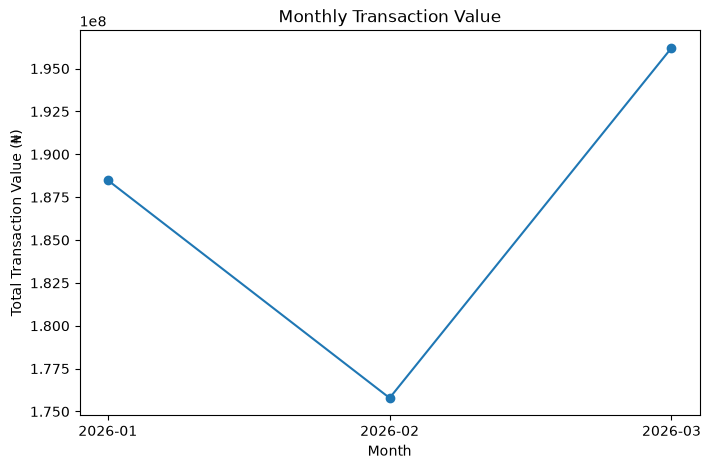

In [172]:
plt.figure(figsize=(8, 5))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Total_Transaction_Value"],
    marker="o"
)

plt.title("Monthly Transaction Value")
plt.xlabel("Month")
plt.ylabel("Total Transaction Value (₦)")
plt.show()

## Finding — Monthly Transaction Trend

The monthly analysis shows that transaction activity declined from January to February before recovering in March.

January recorded 4,133 transactions with a total transaction value of approximately ₦188.49 million. February recorded 3,734 transactions and approximately ₦175.79 million in transaction value, representing a decline from January. Activity increased again in March to 4,133 transactions, while transaction value rose to approximately ₦196.20 million, the highest monthly value during the analysis period.

This validates the Week 2 finding that March recorded the highest transaction value and provides additional evidence of the February decline and March recovery.

In [173]:
customer_activity = (
    df
    .groupby("Customer_ID")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum"),
        Average_Transaction_Value=("Amount_NGN", "mean")
    )
    .reset_index()
)

customer_activity.describe()

,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value
count,1500.000000,1.500000e+03,1500.000000
mean,8.000000,3.736516e+05,46278.209151
std,2.863588,2.786802e+05,33075.270007
min,1.000000,6.151500e+02,307.575000
25%,6.000000,1.537660e+05,22987.011771
50%,8.000000,3.148945e+05,39456.745167
75%,10.000000,5.356223e+05,62110.655000
max,20.000000,1.713943e+06,257274.080000


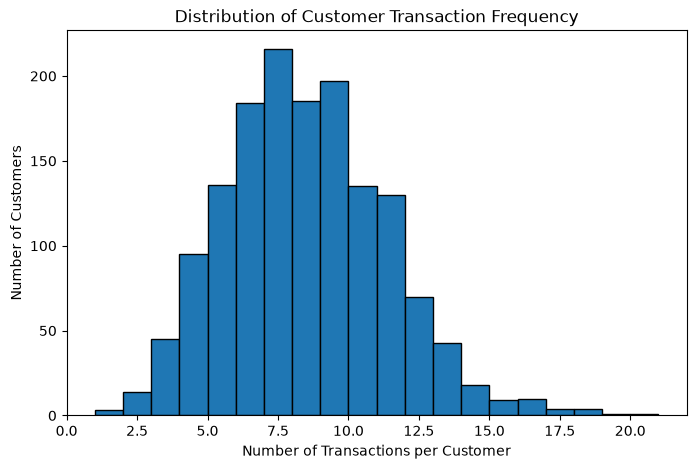

In [174]:
plt.figure(figsize=(8, 5))

plt.hist(
    customer_activity["Transaction_Count"],
    bins=range(
        customer_activity["Transaction_Count"].min(),
        customer_activity["Transaction_Count"].max() + 2
    ),
    edgecolor="black"
)

plt.title("Distribution of Customer Transaction Frequency")
plt.xlabel("Number of Transactions per Customer")
plt.ylabel("Number of Customers")
plt.show()

## Finding — Customer Transaction Frequency

The customer-level analysis shows that all 1,500 customers recorded at least one transaction during the analysis period. Customers completed an average of 8 transactions, with transaction frequency ranging from 1 to 20 transactions per customer.

The median transaction frequency was also 8 transactions, indicating that the central customer activity level was consistent with the overall average. The average total transaction value per customer was approximately ₦373,651.57, while the highest customer-level transaction total was approximately ₦1.71 million.

This analysis provides additional insight into customer activity by moving beyond aggregate transaction volumes and examining transaction behaviour at the individual customer level.

In [175]:
risk_channel_analysis = (
    df
    .groupby("Channel")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Risk_Review_Transactions=(
            "Risk_Review_Flag",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

risk_channel_analysis["Risk_Review_Rate"] = (
    risk_channel_analysis["Risk_Review_Transactions"]
    / risk_channel_analysis["Transaction_Count"]
    * 100
)

risk_channel_analysis = risk_channel_analysis.sort_values(
    "Risk_Review_Rate",
    ascending=False
)

risk_channel_analysis

,Channel,Transaction_Count,Risk_Review_Transactions,Risk_Review_Rate
4,Web,1869,399,21.348315
0,ATM,1747,370,21.179164
1,Mobile App,5102,990,19.404155
2,POS,2393,439,18.345173
3,USSD,889,154,17.322835


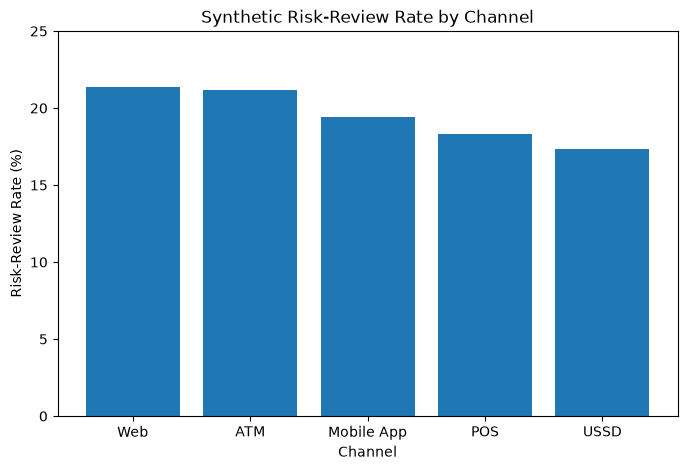

In [176]:
plt.figure(figsize=(8, 5))

plt.bar(
    risk_channel_analysis["Channel"],
    risk_channel_analysis["Risk_Review_Rate"]
)

plt.title("Synthetic Risk-Review Rate by Channel")
plt.xlabel("Channel")
plt.ylabel("Risk-Review Rate (%)")
plt.ylim(0, 25)
plt.xticks(rotation=0)
plt.show()

## Finding — Synthetic Risk-Review Patterns by Channel

The analysis shows that Web transactions had the highest synthetic risk-review rate at approximately 21.35%, closely followed by ATM transactions at 21.18%. USSD recorded the lowest rate at approximately 17.32%.

Mobile App recorded the largest number of risk-review-labelled transactions, with 990 transactions, largely reflecting its substantially higher transaction volume. However, its risk-review rate of approximately 19.40% was below Web and ATM.

This analysis demonstrates the importance of considering both transaction volume and rate when interpreting categorical patterns. As with the transaction-type analysis, the Risk_Review_Flag is a synthetic educational variable and should not be interpreted as evidence of actual fraud or suspicious activity.

In [177]:
print("PYTHON VALIDATION CHECK")
print("-" * 40)

print("Total transactions:", df["Transaction_ID"].count())
print("Total transaction value:", round(df["Amount_NGN"].sum(), 2))
print("Average transaction value:", round(df["Amount_NGN"].mean(), 2))

print("\nCustomer count:", df["Customer_ID"].nunique())
print("Average transactions per customer:",
      round(customer_activity["Transaction_Count"].mean(), 2))

print("\nMonthly transaction values:")
print(monthly_analysis[["Month", "Total_Transaction_Value"]])

print("\nChannel success rates:")
print(
    channel_analysis[["Channel", "Success_Rate"]]
)

PYTHON VALIDATION CHECK
----------------------------------------
Total transactions: 12000
Total transaction value: 560477354.85
Average transaction value: 46706.45

Customer count: 1500
Average transactions per customer: 8.0

Monthly transaction values:
     Month  Total_Transaction_Value
0  2026-01             1.884894e+08
1  2026-02             1.757869e+08
2  2026-03             1.962010e+08

Channel success rates:
      Channel  Success_Rate
1  Mobile App     89.749118
2         POS     90.848308
4         Web     90.850722
0         ATM     91.700057
3        USSD     90.326209


## Week 4 retesting note: timestamp parsing

The SQLite database stores `Transaction_DateTime` as month/day/year and hour:minute (for example, `1/2/2026 0:07`). The Week 4 retest parsed all 12,000 timestamps using `format="%m/%d/%Y %H:%M"` with zero failures. The previous `dayfirst=True` approach failed to parse 7,201 values and assigned a different month to 11,600 records when compared with the explicit format. Use the corrected parsing cells above before relying on monthly Python trends.

Retested monthly totals from SQLite and correctly parsed Python timestamps:

- January 2026: 4,133 transactions; ₦188,489,434.69
- February 2026: 3,734 transactions; ₦175,786,896.99
- March 2026: 4,133 transactions; ₦196,201,023.17

These figures are database-verified. The notebook should still be run from top to bottom in its intended environment to confirm complete end-to-end reproducibility.